Notebook 07 — Backtesting the Deep Learning Signals


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})


Mounted at /content/drive


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AI_Trading_Dissertation"
FINAL_PROJECT_PATH = PROJECT_PATH + "/Final_Project"

RESULTS_PATH = FINAL_PROJECT_PATH + "/04_Results"
PREDICTIONS_PATH = RESULTS_PATH + "/Predictions"
FINAL_TABLES_PATH = RESULTS_PATH + "/Final_Tables"
FIGURES_PATH = FINAL_PROJECT_PATH + "/05_Figures"

os.makedirs(FINAL_TABLES_PATH, exist_ok=True)

LABELS = ["Buy", "Hold", "Sell"]
SIGNAL_TO_POSITION = {"Buy": 1, "Hold": 0, "Sell": -1}

PRIMARY_COST_BPS = 5
COST_LEVELS_BPS = [0, 2, 5, 10, 20]
RISK_FREE_ANNUAL = 0.065

# Transferred from Notebook 05b's validation-selected configuration
TRANSFERRED_THRESHOLD = 0.50
TRANSFERRED_MIN_HOLD = 26

DL_MODELS = ["LSTM", "Transformer"]

# ===== Which deep learning run to backtest =====
# "v2" = the stabilised run from Notebook 06b (19/20 models converged)
# "v1" = the original run from Notebook 06
DL_RUN = "v2"

SUFFIX = "_dl_v2_predictions.parquet" if DL_RUN == "v2" else "_dl_predictions.parquet"
dl_files = sorted(glob.glob(os.path.join(PREDICTIONS_PATH, "*" + SUFFIX)))
stock_names = [os.path.basename(f).replace(SUFFIX, "") for f in dl_files]

print(f"Backtesting deep learning run: {DL_RUN}")

print(f"Deep learning prediction files found: {len(stock_names)}")
print(stock_names)

if len(stock_names) < 10:
    print("\n*** Fewer than 10 stocks - Notebook 07 may not have finished. Re-run it before continuing. ***")


Backtesting deep learning run: v2
Deep learning prediction files found: 10
['Eicher_Motors', 'HDFCB', 'Hindustan_Unilever', 'ICICIBC', 'INFOSYS', 'ITC', 'Mahindra_and_Mahindra', 'ONGC', 'Reliance', 'TCS']


In [ ]:
_s = pd.read_parquet(dl_files[0])
print("Columns available:", _s.columns.tolist())

_span_days = (_s["datetime"].max() - _s["datetime"].min()).days
BARS_PER_YEAR = len(_s) / _span_days * 365.25
print(f"\nBars per year: {BARS_PER_YEAR:.0f}")
print(f"Test bars per stock: {len(_s):,}  (63 fewer than the tree models - the first")
print("window's worth of bars cannot be predicted, since they have no history behind them)")


Columns available: ['datetime', 'close', 'future_return', 'target_signal', 'pred_LSTM', 'prob_LSTM_Buy', 'prob_LSTM_Hold', 'prob_LSTM_Sell', 'pred_Transformer', 'prob_Transformer_Buy', 'prob_Transformer_Hold', 'prob_Transformer_Sell']

Bars per year: 6879
Test bars per stock: 14,426  (63 fewer than the tree models - the first
window's worth of bars cannot be predicted, since they have no history behind them)


In [ ]:
def probabilities_to_positions(proba, classes, threshold, min_hold):
    best_idx = proba.argmax(axis=1)
    best_prob = proba.max(axis=1)
    raw_signal = classes[best_idx]

    desired = np.array([SIGNAL_TO_POSITION.get(s, 0) for s in raw_signal])
    desired[best_prob < threshold] = 0

    if min_hold <= 1:
        return desired

    positions = np.zeros(len(desired), dtype=int)
    current, bars_held = 0, 0
    for i in range(len(desired)):
        if current == 0:
            current = desired[i]
            bars_held = 0 if current == 0 else 1
        else:
            bars_held += 1
            if bars_held >= min_hold and desired[i] != current:
                current = desired[i]
                bars_held = 0 if current == 0 else 1
        positions[i] = current
    return positions


def backtest_positions(close, positions, cost_bps, bars_per_year=None):
    if bars_per_year is None:
        bars_per_year = BARS_PER_YEAR

    close = pd.Series(np.asarray(close, dtype=float))
    market_return = close.pct_change()

    pos = pd.Series(positions).shift(1).fillna(0)          # act only from the next bar
    turnover = pos.diff().abs().fillna(pos.abs())
    cost = turnover * (cost_bps / 10000.0)

    gross = pos * market_return
    net = gross - cost

    valid = market_return.notna()
    net, gross, pos_v, mkt, turn = net[valid], gross[valid], pos[valid], market_return[valid], turnover[valid]

    equity = (1 + net).cumprod()
    bh_equity = (1 + mkt).cumprod()

    years = len(net) / bars_per_year
    fe = equity.iloc[-1]
    cagr = fe ** (1 / years) - 1 if fe > 0 and years > 0 else np.nan

    rf_bar = RISK_FREE_ANNUAL / bars_per_year
    excess = net - rf_bar
    sharpe = (excess.mean() / excess.std()) * np.sqrt(bars_per_year) if excess.std() > 0 else np.nan
    if sharpe is not None and not np.isnan(sharpe) and abs(sharpe) > 100:
        sharpe = np.nan                                     # degenerate (never traded)

    traded = gross[pos_v != 0]

    return {
        "Total_Return": round(float(equity.iloc[-1] - 1), 4),
        "CAGR": round(float(cagr), 4) if not np.isnan(cagr) else np.nan,
        "Sharpe": round(float(sharpe), 3) if sharpe is not None and not np.isnan(sharpe) else np.nan,
        "Max_Drawdown": round(float((equity / equity.cummax() - 1).min()), 4),
        "BuyHold_Return": round(float(bh_equity.iloc[-1] - 1), 4),
        "Position_Changes": int((turn > 0).sum()),
        "Turnover_Units": round(float(turn.sum()), 1),
        "Time_In_Market": round(float((pos_v != 0).mean()), 3),
        "Win_Rate": round(float((traded > 0).mean()), 4) if len(traded) else np.nan,
        "N_Bars": int(len(net)),
    }, equity


In [ ]:
dl_rows = []
dl_equity = {}

for stock in stock_names:
    df = pd.read_parquet(os.path.join(PREDICTIONS_PATH, f"{stock}{SUFFIX}"))
    close = df["close"].values
    print(f"\n{stock}  ({len(df):,} bars)")

    for model in DL_MODELS:
        prob_cols = [f"prob_{model}_{lab}" for lab in LABELS]
        if not all(c in df.columns for c in prob_cols):
            print(f"  !! probabilities for {model} not found - skipping")
            continue

        proba = df[prob_cols].values
        classes = np.array(LABELS)

        # --- variant A: act on every bar (no confidence filter, no hold period) ---
        pos_raw = probabilities_to_positions(proba, classes, threshold=0.0, min_hold=1)

        # --- variant B: transferred configuration from Notebook 05b ---
        pos_thr = probabilities_to_positions(proba, classes, TRANSFERRED_THRESHOLD, TRANSFERRED_MIN_HOLD)

        for variant, positions in [("Every bar", pos_raw), ("Thresholded", pos_thr)]:
            for cost in COST_LEVELS_BPS:
                m, equity = backtest_positions(close, positions, cost)
                m.update({"Stock": stock, "Model": model, "Variant": variant, "Cost_BPS": cost})
                dl_rows.append(m)
                if cost == PRIMARY_COST_BPS and variant == "Thresholded":
                    dl_equity[(stock, model)] = (df["datetime"].values[1:], equity.values)

        a = [r for r in dl_rows if r["Stock"] == stock and r["Model"] == model
             and r["Variant"] == "Every bar" and r["Cost_BPS"] == PRIMARY_COST_BPS][0]
        b = [r for r in dl_rows if r["Stock"] == stock and r["Model"] == model
             and r["Variant"] == "Thresholded" and r["Cost_BPS"] == PRIMARY_COST_BPS][0]
        print(f"  {model:12s} every-bar {a['Total_Return']:>8.2%} (turn {a['Turnover_Units']:>6.0f})   "
              f"thresholded {b['Total_Return']:>8.2%} (turn {b['Turnover_Units']:>6.0f})")

dl_bt = pd.DataFrame(dl_rows)
dl_bt.to_csv(os.path.join(RESULTS_PATH, f"Backtest_DL_Full_{DL_RUN}.csv"), index=False)
print(f"\nSaved {len(dl_bt)} deep learning backtest results.")



Eicher_Motors  (14,426 bars)
  LSTM         every-bar   -1.19% (turn    712)   thresholded   -5.73% (turn     68)
  Transformer  every-bar  -42.62% (turn    986)   thresholded    8.76% (turn     42)

HDFCB  (14,524 bars)
  LSTM         every-bar  -66.63% (turn   2039)   thresholded   -0.89% (turn      2)
  Transformer  every-bar  -44.79% (turn   1265)   thresholded    0.00% (turn      0)

Hindustan_Unilever  (14,515 bars)
  LSTM         every-bar  -51.97% (turn   2357)   thresholded  -39.30% (turn    220)
  Transformer  every-bar  -64.53% (turn   2493)   thresholded   -4.92% (turn    124)

ICICIBC  (14,544 bars)
  LSTM         every-bar  -44.86% (turn   1200)   thresholded   -0.19% (turn      2)
  Transformer  every-bar  -28.72% (turn    494)   thresholded    0.00% (turn      0)

INFOSYS  (14,544 bars)
  LSTM         every-bar  -71.54% (turn   2831)   thresholded    4.57% (turn    447)
  Transformer  every-bar  -58.06% (turn   1851)   thresholded  -13.18% (turn    176)

ITC  (14,543 b

In [ ]:
orig = pd.read_csv(os.path.join(RESULTS_PATH, "Backtest_Results_Full.csv"))
thresh = pd.read_csv(os.path.join(RESULTS_PATH, "Backtest_Thresholded_Test.csv"))

# Normalise the three sources into one long table
a = orig[["Stock", "Model", "Cost_BPS", "Total_Return", "Sharpe", "Max_Drawdown", "Time_In_Market"]].copy()
a["Variant"] = "Every bar"
a["Turnover_Units"] = orig["Total_Cost_Paid"] / (PRIMARY_COST_BPS / 10000)

b = thresh[["Stock", "Model", "Cost_BPS", "Total_Return", "Sharpe", "Max_Drawdown", "Time_In_Market", "Turnover_Units"]].copy()
b["Variant"] = "Thresholded"

c = dl_bt[["Stock", "Model", "Cost_BPS", "Total_Return", "Sharpe", "Max_Drawdown", "Time_In_Market", "Turnover_Units", "Variant"]].copy()

everything = pd.concat([a, b, c], ignore_index=True)
everything["Sharpe"] = everything["Sharpe"].where(everything["Sharpe"].abs() <= 100)
everything.to_csv(os.path.join(RESULTS_PATH, "Backtest_AllModels_Long.csv"), index=False)

print("Combined rows:", len(everything))
print("Models present:", sorted(everything["Model"].unique()))


Combined rows: 550
Models present: ['Baseline_Majority', 'Baseline_Momentum', 'Baseline_Random', 'LSTM', 'RandomForest', 'Transformer', 'XGBoost']


In [ ]:
bh = orig[orig["Cost_BPS"] == PRIMARY_COST_BPS]["BuyHold_Return"].mean()

MODEL_ORDER = ["Baseline_Random", "Baseline_Majority", "Baseline_Momentum",
               "RandomForest", "XGBoost", "LSTM", "Transformer"]

rows = []
for model in MODEL_ORDER:
    for variant in ["Every bar", "Thresholded"]:
        sub = everything[(everything["Model"] == model) & (everything["Variant"] == variant)
                         & (everything["Cost_BPS"] == PRIMARY_COST_BPS)]
        if len(sub) == 0:
            continue
        rows.append({
            "Model": model, "Variant": variant,
            "Return_%": round(sub["Total_Return"].mean() * 100, 2),
            "Sharpe": round(sub["Sharpe"].mean(skipna=True), 3),
            "MaxDD_%": round(sub["Max_Drawdown"].mean() * 100, 2),
            "Turnover": round(sub["Turnover_Units"].mean(), 0),
            "InMkt_%": round(sub["Time_In_Market"].mean() * 100, 1),
            "Beats_BH": "Yes" if sub["Total_Return"].mean() > bh else "No",
        })

rows.append({"Model": "Buy & Hold", "Variant": "—", "Return_%": round(bh * 100, 2),
             "Sharpe": np.nan, "MaxDD_%": np.nan, "Turnover": 2, "InMkt_%": 100.0, "Beats_BH": "—"})

table_all = pd.DataFrame(rows)
table_all.to_csv(os.path.join(FINAL_TABLES_PATH, f"Table6_AllModels_Trading_{DL_RUN}.csv"), index=False)
print(f"All models at {PRIMARY_COST_BPS} bps per side  (buy & hold = {bh*100:.2f}%)\n")
table_all


All models at 5 bps per side  (buy & hold = -3.33%)



,Model,Variant,Return_%,Sharpe,MaxDD_%,Turnover,InMkt_%,Beats_BH
0,Baseline_Random,Every bar,-99.87,-15.743,-99.87,13328.0,72.0,No
1,Baseline_Majority,Every bar,-6.29,-0.328,-35.23,1.0,100.0,No
2,Baseline_Momentum,Every bar,-99.98,-20.341,-99.98,15224.0,94.5,No
3,RandomForest,Every bar,-78.71,-4.183,-80.60,4670.0,65.8,No
4,RandomForest,Thresholded,-9.83,-0.985,-22.19,328.0,28.2,No
5,XGBoost,Every bar,-91.13,-5.452,-91.46,5751.0,82.8,No
6,XGBoost,Thresholded,-40.49,-1.348,-50.33,995.0,89.9,No
7,LSTM,Every bar,-47.43,-2.232,-53.60,1826.0,49.9,No
8,LSTM,Thresholded,-7.03,-3.721,-13.76,153.0,13.2,No
9,Transformer,Every bar,-44.96,-2.206,-49.26,1577.0,45.0,No


In [ ]:
def breakeven(series_pct, benchmark_pct):
    costs = series_pct.index.values.astype(float)
    vals = series_pct.values
    above = vals > benchmark_pct
    if not above.any():
        return np.nan
    if above.all():
        return float(costs.max())
    last_ok = costs[above].max()
    worse = costs[~above & (costs > last_ok)]
    if len(worse) == 0:
        return float(last_ok)
    lo, hi = last_ok, worse.min()
    v_lo, v_hi = vals[costs == lo][0], vals[costs == hi][0]
    frac = (v_lo - benchmark_pct) / (v_lo - v_hi) if v_lo != v_hi else 0
    return round(lo + frac * (hi - lo), 2)


be_rows = []
for model in MODEL_ORDER:
    for variant in ["Every bar", "Thresholded"]:
        sub = everything[(everything["Model"] == model) & (everything["Variant"] == variant)]
        if len(sub) == 0:
            continue
        series = sub.groupby("Cost_BPS")["Total_Return"].mean() * 100
        be_rows.append({
            "Model": model, "Variant": variant,
            "Return_0bps_%": round(series.get(0, np.nan), 2),
            "Return_5bps_%": round(series.get(5, np.nan), 2),
            "Breakeven_bps": breakeven(series, bh * 100),
        })

be_table = pd.DataFrame(be_rows).sort_values("Breakeven_bps", ascending=False, na_position="last")
be_table.to_csv(os.path.join(FINAL_TABLES_PATH, f"Table7_Breakeven_AllModels_{DL_RUN}.csv"), index=False)

print("Break-even transaction cost — the level at which each strategy stops beating buy & hold.")
print("NaN means it never beats the benchmark at any cost level tested.\n")
be_table


Break-even transaction cost — the level at which each strategy stops beating buy & hold.
NaN means it never beats the benchmark at any cost level tested.



,Model,Variant,Return_0bps_%,Return_5bps_%,Breakeven_bps
10,Transformer,Thresholded,1.92,-5.92,3.28
4,RandomForest,Thresholded,6.09,-9.83,2.85
8,LSTM,Thresholded,0.43,-7.03,2.44
3,RandomForest,Every bar,100.93,-78.71,1.72
7,LSTM,Every bar,18.98,-47.43,1.25
5,XGBoost,Every bar,54.32,-91.13,1.09
9,Transformer,Every bar,12.35,-44.96,1.02
6,XGBoost,Thresholded,-2.08,-40.49,0.14
0,Baseline_Random,Every bar,-0.67,-99.87,0.06
1,Baseline_Majority,Every bar,-6.24,-6.29,NaN


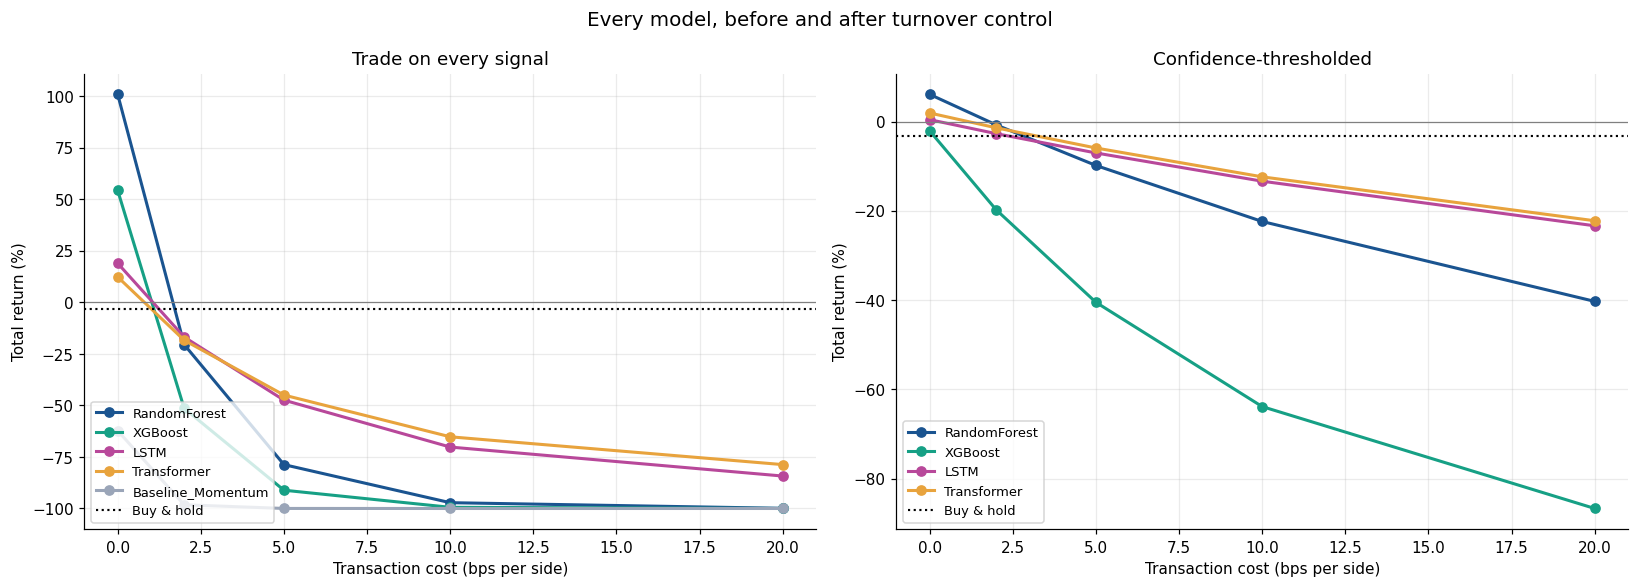

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))

palette = {
    "RandomForest": "1a5490", "XGBoost": "16a085",
    "LSTM": "b8489a", "Transformer": "e8a33d",
    "Baseline_Momentum": "9aa5b8",
}

for ax, variant, title in [
    (axes[0], "Every bar", "Trade on every signal"),
    (axes[1], "Thresholded", "Confidence-thresholded"),
]:
    for model, colour in palette.items():
        sub = everything[(everything["Model"] == model) & (everything["Variant"] == variant)]
        if len(sub) == 0:
            continue
        series = sub.groupby("Cost_BPS")["Total_Return"].mean() * 100
        ax.plot(series.index, series.values, marker="o", linewidth=2,
                color="#" + colour, label=model)

    ax.axhline(bh * 100, color="black", linestyle=":", linewidth=1.4, label="Buy & hold")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel("Transaction cost (bps per side)")
    ax.set_ylabel("Total return (%)")
    ax.set_title(title, fontsize=12)
    ax.legend(fontsize=8.5, loc="lower left")

plt.suptitle("Every model, before and after turnover control", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, f"fig6_all_models_cost_{DL_RUN}.png"), dpi=200, bbox_inches="tight")
plt.show()


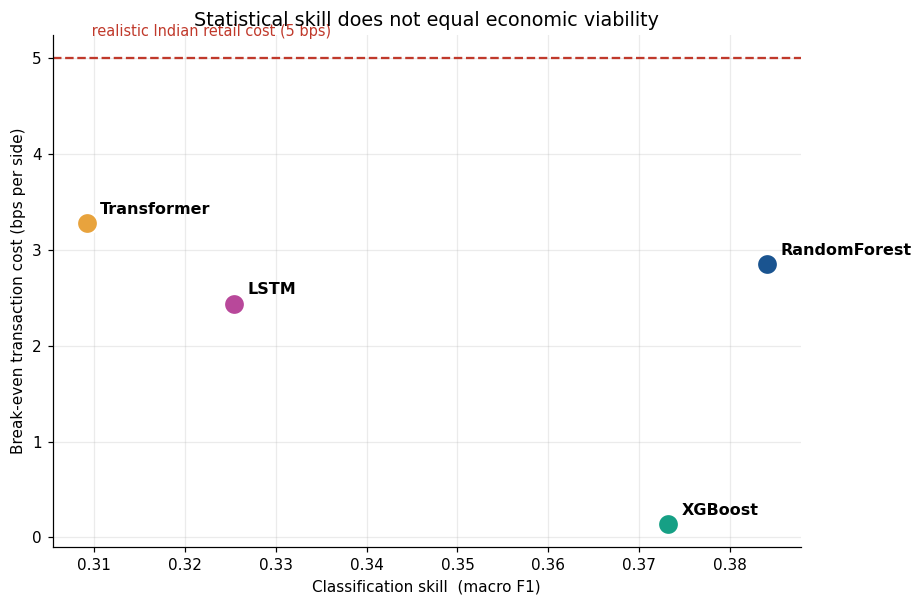

In [ ]:
clf = pd.read_csv(os.path.join(RESULTS_PATH, "All_Models_Metrics_v2.csv" if DL_RUN == "v2" else "All_Models_Metrics.csv"))
clf_mean = clf.groupby("Model")["F1_Macro"].mean()

merged = be_table[be_table["Variant"] == "Thresholded"].set_index("Model").join(clf_mean)
merged = merged.dropna(subset=["F1_Macro"])

fig, ax = plt.subplots(figsize=(8.5, 5.6))

for model, row in merged.iterrows():
    be_val = row["Breakeven_bps"] if not np.isnan(row["Breakeven_bps"]) else 0
    colour = "#" + palette.get(model, "9aa5b8")
    ax.scatter(row["F1_Macro"], be_val, s=190, color=colour, zorder=3, edgecolor="white", linewidth=1.5)
    ax.annotate(model, (row["F1_Macro"], be_val), xytext=(9, 6),
                textcoords="offset points", fontsize=10.5, fontweight="bold")

ax.axhline(5, color="#c0392b", linestyle="--", linewidth=1.5)
ax.text(merged["F1_Macro"].min(), 5.2, " realistic Indian retail cost (5 bps)",
        color="#c0392b", fontsize=9.5, va="bottom")

ax.set_xlabel("Classification skill  (macro F1)")
ax.set_ylabel("Break-even transaction cost (bps per side)")
ax.set_title("Statistical skill does not equal economic viability", fontsize=12.5)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, f"fig7_skill_vs_viability_{DL_RUN}.png"), dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
sens_rows = []

for stock in stock_names:
    df = pd.read_parquet(os.path.join(PREDICTIONS_PATH, f"{stock}{SUFFIX}"))
    close = df["close"].values
    for model in DL_MODELS:
        prob_cols = [f"prob_{model}_{lab}" for lab in LABELS]
        if not all(c in df.columns for c in prob_cols):
            continue
        proba = df[prob_cols].values
        for thr in [0.34, 0.40, 0.45, 0.50, 0.55, 0.60]:
            for mh in [1, 8, 26]:
                pos = probabilities_to_positions(proba, np.array(LABELS), thr, mh)
                m, _ = backtest_positions(close, pos, PRIMARY_COST_BPS)
                sens_rows.append({"Stock": stock, "Model": model, "Threshold": thr,
                                  "Min_Hold": mh, "Total_Return": m["Total_Return"]})

sens = pd.DataFrame(sens_rows)
sens.to_csv(os.path.join(RESULTS_PATH, f"DL_Threshold_Sensitivity_Test_{DL_RUN}.csv"), index=False)

for model in DL_MODELS:
    sub = sens[sens["Model"] == model]
    if len(sub) == 0:
        continue
    grid = sub.groupby(["Threshold", "Min_Hold"])["Total_Return"].mean().unstack() * 100
    print(f"\n{model} — mean test return (%) across the grid.")
    print(f"Applied configuration was threshold {TRANSFERRED_THRESHOLD}, min hold {TRANSFERRED_MIN_HOLD} (transferred, not tuned here):")
    display(grid.round(2))



LSTM — mean test return (%) across the grid.
Applied configuration was threshold 0.5, min hold 26 (transferred, not tuned here):


Min_Hold,1,8,26
Threshold,,,
0.34,-47.39,-42.41,-20.68
0.40,-29.54,-30.87,-20.56
0.45,-15.97,-17.22,-16.00
0.50,-5.86,-4.98,-7.03
0.55,-1.08,-1.93,-2.59
0.60,0.19,2.34,3.72



Transformer — mean test return (%) across the grid.
Applied configuration was threshold 0.5, min hold 26 (transferred, not tuned here):


Min_Hold,1,8,26
Threshold,,,
0.34,-44.68,-38.63,-26.76
0.40,-32.44,-30.96,-20.67
0.45,-20.23,-19.65,-15.82
0.50,-5.27,-7.70,-5.92
0.55,-1.53,-0.75,-0.72
0.60,-0.28,0.54,0.14


In [ ]:
lines = ["=" * 76, "KEY NUMBERS  —  including deep learning", "=" * 76, ""]

lines.append("CLASSIFICATION  (macro F1, mean across 10 stocks)")
for model, val in clf_mean.sort_values(ascending=False).items():
    lines.append(f"  {model:22s} {val:.4f}")

lines.append("")
lines.append(f"TRADING  (thresholded, {PRIMARY_COST_BPS} bps per side; buy & hold = {bh*100:+.2f}%)")
for _, r in be_table[be_table["Variant"] == "Thresholded"].iterrows():
    be_txt = f"{r['Breakeven_bps']:.2f} bps" if not np.isnan(r["Breakeven_bps"]) else "never beats B&H"
    lines.append(f"  {r['Model']:22s} 0bps {r['Return_0bps_%']:>8.2f}%   5bps {r['Return_5bps_%']:>8.2f}%   break-even {be_txt}")

best_f1 = clf_mean.idxmax()
best_be = be_table[be_table["Variant"] == "Thresholded"].dropna(subset=["Breakeven_bps"])
best_be_model = best_be.iloc[0]["Model"] if len(best_be) else "none"

lines += [
    "",
    "HEADLINE",
    f"  Best classifier                : {best_f1} (F1 {clf_mean.max():.4f})",
    f"  Best economically              : {best_be_model}",
    f"  Did deep learning win?         : {'YES' if best_f1 in DL_MODELS else 'NO — tree ensembles matched or beat sequence models'}",
    "",
    "=" * 76,
]

txt = "\n".join(lines)
print(txt)
with open(os.path.join(FINAL_TABLES_PATH, f"KEY_NUMBERS_FINAL_{DL_RUN}.txt"), "w") as f:
    f.write(txt)
print("\nSaved to Final_Tables/KEY_NUMBERS_FINAL.txt")


KEY NUMBERS  —  including deep learning

CLASSIFICATION  (macro F1, mean across 10 stocks)
  RandomForest           0.3841
  XGBoost                0.3732
  Baseline_Random        0.3345
  LSTM                   0.3254
  Transformer            0.3091
  Baseline_Momentum      0.2815
  Baseline_Majority      0.1766

TRADING  (thresholded, 5 bps per side; buy & hold = -3.33%)
  Transformer            0bps     1.92%   5bps    -5.92%   break-even 3.28 bps
  RandomForest           0bps     6.09%   5bps    -9.83%   break-even 2.85 bps
  LSTM                   0bps     0.43%   5bps    -7.03%   break-even 2.44 bps
  XGBoost                0bps    -2.08%   5bps   -40.49%   break-even 0.14 bps

HEADLINE
  Best classifier                : RandomForest (F1 0.3841)
  Best economically              : Transformer
  Did deep learning win?         : NO — tree ensembles matched or beat sequence models


Saved to Final_Tables/KEY_NUMBERS_FINAL.txt
